<a href="https://colab.research.google.com/github/hbprosper/dihiggs/blob/main/code/heft_checks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Higgs Effective Field Theory (HEFT) Study: Checks
> Created: Oct 28, 2026 Pushpa Bhat (Fermilab), Nicola de Filippis (Bari),<br> Kurtis Johnson,  Harrison B. Prosper, Ryne Starnes (FSU), Claude<br>


## Introduction

This notebook checks the data and the test pipeline. Run it after `heft_prepare_data.ipynb`, `heft_train.ipynb` and `heft_test.ipynb`. Every test prints **PASS** or **FAIL**, and a summary is printed at the end. The notebook only reads files; it changes nothing. The plan behind the checks is in `docs/checks_plan.pdf`.

| check | question |
| :--- | :--- |
| 1 | Is every HEFT parameter point in the POWHEG file unique? |
| 2 | Are the holdout spectra disjoint from the data used in training, and was the saved model trained on the current training file? |
| 3 | Does `heft_test.ipynb` compare each POWHEG histogram with the model's prediction for the same parameter point? |

**A note on comparing numbers.** `heft_prepare_data.ipynb` converts the Wilson coefficients and cross sections to 32-bit floats before writing them, and the files store them with different numbers of digits. So wherever values from different files are compared, both are first converted to `float32`; equal `float32` values then compare exactly.

In [1]:
# ------------------------------------------------------------------
# Google Colab setup (nothing happens when run outside Colab)
#   1. clone the dihiggs repository, which holds the data files,
#   2. install the dihiggs package, which also installs drwho,
#   3. make dihiggs/code the working directory so that the relative
#      paths used below (../data, runs/) work as they do locally.
# ------------------------------------------------------------------
import os, sys, subprocess, importlib

IN_COLAB = 'google.colab' in sys.modules

# With USE_DRIVE = True the runs/ folder lives in your Google Drive
# (MyDrive/dihiggs/runs), where heft_train.ipynb saved the trained model.
USE_DRIVE = True

if IN_COLAB:
    REPO = '/content/dihiggs'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q',
                        'https://github.com/hbprosper/dihiggs.git', REPO],
                       check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', REPO],
                   check=True)
    importlib.invalidate_caches()
    os.chdir(f'{REPO}/code')

    if USE_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')
        drive_runs = '/content/drive/MyDrive/dihiggs/runs'
        os.makedirs(drive_runs, exist_ok=True)
        if not os.path.exists('runs'):
            os.symlink(drive_runs, 'runs')
        print(f'runs/ is stored in {drive_runs}')

print(f'working directory: {os.getcwd()}')

working directory: /Users/harry/Projects/Tutorials/GitHub/dihiggs/code


In [2]:
import os, re, json, shutil, hashlib, inspect, tempfile, importlib.util

# the standard module for tabular data
import pandas as pd

# the standard module for array manipulation
import numpy as np

# the standard modules for high-quality plots
import matplotlib as mp
import matplotlib.pyplot as plt

import yaml

# update fonts
plt.rcParams.update({
  "text.usetex": shutil.which('latex') is not None,
  "font.family": "sans-serif",
  "font.size": 12
})

# Every test is recorded here and listed in the summary at the end.
RESULTS = []

def check(name, passed, detail=''):
    passed = bool(passed)
    RESULTS.append((name, passed, detail))
    print(f"{'PASS' if passed else 'FAIL'}  {name}")
    if detail:
        print(f'      {detail}')

## Files and conventions

These must agree with `heft_prepare_data.ipynb` and `heft_train.ipynb`.

In [ ]:
DATA         = '../data'
USE_CLEANED  = False             # must match heft_prepare_data.ipynb
POWHEG_FILE  = (f'{DATA}/powheg_total_gauss_params_13TeV_cleaned.csv.gz' if USE_CLEANED
                else f'{DATA}/powheg_total_gauss_params_13TeV.csv.gz')
HOLDOUT_FILE = f'{DATA}/heft_wide_gauss_testdata_13TeV.csv'
TRAIN_FILE   = f'{DATA}/heft_wide_gauss_traindata_13TeV.csv.gz'
CONFIG_FILE  = 'runs/L1Loss/dihiggs_config.yaml'

N_HOLDOUT = 1000                  # START in heft_prepare_data.ipynb
FIRST_BIN, LAST_BIN = 17, 96      # POWHEG bins used; bin k is [15k, 15(k+1)) GeV
BINS   = [str(k) for k in range(FIRST_BIN, LAST_BIN + 1)]
PARAMS = ['klambda', 'CT', 'CTT', 'CGGH', 'CGGHH']

NEAR = 1e-6                       # near-duplicate threshold, standardised units

# bin centres: in GeV, and as the dimensionless x used by the model
CENTRES_GEV = 15.0 * np.arange(FIRST_BIN, LAST_BIN + 1) + 7.5
CENTRES_X   = (np.arange(len(BINS)) + 0.5) / 100

In [ ]:
powheg  = pd.read_csv(POWHEG_FILE)
holdout = pd.read_csv(HOLDOUT_FILE)
train   = pd.read_csv(TRAIN_FILE)

# In the POWHEG file the first five columns are the Wilson coefficients and
# the last column, ID, identifies each spectrum (1, 2, ...) in every file.
assert 'ID' in powheg.columns, f'{POWHEG_FILE} has no ID column'
POWHEG_IDS = powheg.ID.to_numpy()
ROW = pd.Series(np.arange(len(powheg)), index=POWHEG_IDS)    # ROW[id]: row of that ID

def rows_of(ids):
    '''rows of the POWHEG file holding the given IDs'''
    return ROW.loc[np.asarray(ids)].to_numpy()

theta_powheg   = powheg.iloc[:, :5].to_numpy(np.float64)
ALL_BINS       = [c for c in powheg.columns if c.isdigit()]      # '0' ... '99'
spectra_all32  = powheg[ALL_BINS].to_numpy(np.float32)           # [N, 100]
spectra_used32 = powheg[BINS].to_numpy(np.float32)               # [N, 80]

print(f'POWHEG file:   {len(powheg):7d} spectra ({POWHEG_FILE})')
print(f'holdout file:  {len(holdout):7d} spectra')
print(f'training file: {len(train):7d} rows')

## Check 1: every parameter point in the POWHEG file is unique

A duplicated point $\theta = (\kappa_\lambda, c_t, c_{tt}, c_{ggh}, c_{gghh})$ could land in both the training and the holdout sets, so the holdout would partly test memory rather than generalisation.

### 1a. Exact duplicates
Both as stored and after conversion to `float32`, the precision the pipeline uses.

In [5]:
n64 = pd.DataFrame(theta_powheg).duplicated().sum()
n32 = pd.DataFrame(theta_powheg.astype(np.float32)).duplicated().sum()

check('1a no duplicate parameter points (as stored)', n64 == 0, f'{n64} duplicated rows')
check('1a no duplicate parameter points (float32)',   n32 == 0, f'{n32} duplicated rows')

PASS  1a no duplicate parameter points (as stored)
      0 duplicated rows
PASS  1a no duplicate parameter points (float32)
      0 duplicated rows


### 1b. Near duplicates

Each coefficient is divided by its standard deviation, so that a step of 1 means "one standard deviation of the sampled points" along every axis. Then the distance between every pair of points is computed, about 12.5 million pairs. The differences are taken directly (not via $|a|^2 + |b|^2 - 2a\cdot b$, which loses all precision for nearly equal points).

In [ ]:
z = theta_powheg / theta_powheg.std(axis=0)
n = len(z)

nearest = np.full(n, np.inf)     # distance from each point to its nearest neighbour
partner = np.zeros(n, dtype=int) # ... and which point that is
close_pairs = []                 # pairs closer than NEAR

for i in range(n - 1):
    d = np.sqrt(((z[i+1:] - z[i])**2).sum(axis=1))   # distances to points i+1, ..., n-1

    j = np.argmin(d)
    if d[j] < nearest[i]:
        nearest[i], partner[i] = d[j], i + 1 + j

    closer = d < nearest[i+1:]                         # is i the nearest so far for them?
    nearest[i+1:][closer] = d[closer]
    partner[i+1:][closer] = i

    close_pairs += [(i, i + 1 + k) for k in np.nonzero(d < NEAR)[0]]

check(f'1b no pair of points closer than {NEAR:g} (standardised units)',
      len(close_pairs) == 0,
      f'{len(close_pairs)} such pairs; smallest distance {nearest.min():.3g}')

# the five closest pairs
order = np.argsort(nearest)
closest = []                       # pairs, closest first
print('\nclosest pairs (standardised distance, IDs):')
for i in order:
    pair = (min(i, partner[i]), max(i, partner[i]))
    if pair not in closest:
        closest.append(pair)
        print(f'  {nearest[i]:.4f}   ID {POWHEG_IDS[pair[0]]} and ID {POWHEG_IDS[pair[1]]}')
    if len(closest) == 5:
        break

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(nearest, bins=60)
ax.set_xlabel('distance to nearest neighbour (standardised)')
ax.set_ylabel('number of points')
ax.grid(alpha=0.3)
plt.show()

### 1c. Duplicate spectra
Two different parameter points with identical cross sections in all 100 bins would indicate a copying error when the file was produced.

In [7]:
nd = powheg.duplicated(subset=ALL_BINS).sum()
check('1c no two parameter points share an identical spectrum', nd == 0, f'{nd} duplicated spectra')

PASS  1c no two parameter points share an identical spectrum
      0 duplicated spectra


### 1d. Spectra of the closest pairs (by eye)
Nearby points should have similar spectra. A large difference would mean that parameters and spectra are attached to the wrong rows.

In [ ]:
pairs = closest[:3]
fig, axes = plt.subplots(1, len(pairs), figsize=(4 * len(pairs), 3.2))
edges = np.arange(255, 1456, 15)
for ax, (i, j) in zip(np.atleast_1d(axes), pairs):
    for k, c in ((i, 'C0'), (j, 'C1')):
        ax.stairs(spectra_used32[k], edges, color=c, label=f'ID {POWHEG_IDS[k]}', baseline=None)
    ax.set_yscale('log')
    ax.set_title(f'distance {np.linalg.norm(z[i] - z[j]):.3f}', fontsize=10)
    ax.set_xlabel(r'$m_{hh}$ [GeV]')
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Check 2: the holdout spectra are disjoint from the training data

`heft_prepare_data.ipynb` gives each POWHEG row an `ID` (its row number), shuffles the rows with a fixed seed, writes the first `N_HOLDOUT` to the holdout file, and dices the rest into one row per bin for the training file.

### 2a. Counts

In [ ]:
ids_holdout = holdout.ID.to_numpy()
ids_train   = np.unique(train.ID.to_numpy())

check(f'2a holdout file has {N_HOLDOUT} spectra', len(holdout) == N_HOLDOUT, f'{len(holdout)} rows')
check('2a holdout IDs are distinct', len(np.unique(ids_holdout)) == len(holdout))
check(f'2a training file has {len(powheg) - N_HOLDOUT} spectra',
      len(ids_train) == len(powheg) - N_HOLDOUT, f'{len(ids_train)} distinct IDs')

# each training spectrum contributes one row per non-zero bin
nonzero = (spectra_used32 > 0).sum(axis=1)
expected = nonzero[rows_of(ids_train)].sum()
check('2a training rows = non-zero bins of the training spectra',
      len(train) == expected, f'{len(train)} rows, expected {expected}')

### 2b. Disjoint by ID

In [ ]:
common = np.intersect1d(ids_holdout, ids_train)
check('2b no ID is in both the holdout and the training file', len(common) == 0,
      f'{len(common)} IDs in both')
check('2b together they cover every POWHEG spectrum exactly once',
      np.array_equal(np.sort(np.concatenate((ids_holdout, ids_train))), np.sort(POWHEG_IDS)))

### 2c. Disjoint by value
IDs could be mislabelled, so repeat the test with the parameter values themselves.

In [11]:
def theta_set(df):
    return set(map(tuple, df[PARAMS].to_numpy(np.float32).tolist()))

shared = theta_set(holdout) & theta_set(train)
check('2c no parameter point is in both files (float32 values)', len(shared) == 0,
      f'{len(shared)} shared points')

PASS  2c no parameter point is in both files (float32 values)
      0 shared points


### 2d. Each file is a faithful copy of the POWHEG file
For every holdout row: the same coefficients and the same 80 cross sections as POWHEG row `ID`. For every training row: the coefficients of POWHEG row `ID`, a mass value $x$ that is a bin centre $x = (k - 17 + \frac12)/100$, and the cross section of POWHEG row `ID`, bin $k$.

In [ ]:
# holdout
p = powheg.iloc[rows_of(ids_holdout)]
check('2d holdout coefficients equal the POWHEG coefficients',
      np.array_equal(holdout[PARAMS].to_numpy(np.float32), p.iloc[:, :5].to_numpy(np.float32)))
check('2d holdout spectra equal the POWHEG spectra',
      np.array_equal(holdout[BINS].to_numpy(np.float32), p[BINS].to_numpy(np.float32)))

# training
tid  = train.ID.to_numpy()
trow = rows_of(tid)              # POWHEG row of each training row
check('2d training coefficients equal the POWHEG coefficients',
      np.array_equal(train[PARAMS].to_numpy(np.float32), theta_powheg[trow].astype(np.float32)))

x = train.mhh.to_numpy()
k = np.rint((x - 0.005) * 100).astype(int) + FIRST_BIN          # bin number of each row
on_centre = np.allclose(x, (k - FIRST_BIN + 0.5) / 100, rtol=0, atol=1e-12)
check('2d every training mass is a bin centre in bins 17-96',
      on_centre and k.min() >= FIRST_BIN and k.max() <= LAST_BIN)

check('2d training cross sections equal POWHEG row ID, bin k',
      np.array_equal(train.sigma.to_numpy(np.float32), spectra_all32[trow, k]))

per_bin = pd.Series(1, index=pd.MultiIndex.from_arrays([tid, k])).groupby(level=[0, 1]).size()
counts  = train.groupby('ID').size()
check('2d each spectrum appears once per non-zero bin, no bin twice',
      per_bin.max() == 1 and np.array_equal(counts.to_numpy(), nonzero[rows_of(counts.index)]))

### 2e. No leak inside the training notebook
`heft_train.ipynb` must name no data file other than the training file, and the `drwho` classes that build the datasets must not read files.

In [13]:
with open('heft_train.ipynb') as f:
    train_nb = json.load(f)
train_code = '\n'.join(''.join(c['source']) for c in train_nb['cells'] if c['cell_type'] == 'code')
named = sorted(set(re.findall(r'heft_wide_gauss_\w+\.csv(?:\.gz)?', train_code)))
check('2e heft_train.ipynb names only the training file',
      named == [os.path.basename(TRAIN_FILE)], f'data files named: {named}')

import drwho.data as dat
source = inspect.getsource(dat.Dataset) + inspect.getsource(dat.DataLoader)
reads = [w for w in ('open(', 'read_csv', 'np.load', 'loadtxt', 'torch.load') if w in source]
check('2e drwho Dataset and DataLoader do not read files', not reads, f'found: {reads}')

PASS  2e heft_train.ipynb names only the training file
      data files named: ['heft_wide_gauss_traindata_13TeV.csv.gz']
PASS  2e drwho Dataset and DataLoader do not read files
      found: []


### 2f. The saved model was trained on the current training file
`heft_train.ipynb` records a fingerprint (SHA-256) of the training file in the configuration. If the configuration predates that change, the weaker test is that the model's training, validation and test sizes add up to the current file's length.

In [14]:
with open(CONFIG_FILE) as f:
    cfg = yaml.safe_load(f)
with open(TRAIN_FILE, 'rb') as f:
    sha = hashlib.sha256(f.read()).hexdigest()

if 'traindata_sha256' in cfg:
    check('2f the saved model was trained on the current training file',
          cfg['traindata_sha256'] == sha,
          f"model: {cfg['traindata_sha256'][:12]}...  file: {sha[:12]}...")
else:
    total = cfg['train_size'] + cfg['val_size'] + cfg['test_size']
    check('2f (weak test) the model\'s data sizes add up to the current training file',
          total == len(train),
          f'{total} vs {len(train)} rows. No fingerprint recorded: retrain with the '
          'current heft_train.ipynb for the full test')

PASS  2f the saved model was trained on the current training file
      model: 4c3a168a7dc7...  file: 4c3a168a7dc7...


## Check 3: the test notebook compares like with like

The function `get_spectra` is taken from `heft_test.ipynb` itself and run on every holdout spectrum. Its results are compared with an independent calculation:
 * the POWHEG spectrum is taken from the **POWHEG file** by `ID`, not from the holdout file;
 * the prediction comes from the **exported numpy copy** of the model (`dihiggs/templates/heftnet_numpy.py`), which takes $m_{hh}$ in GeV and builds its inputs with different code.

The notebook's model runs in 32-bit arithmetic and the copy in 64-bit, so their predictions are not identical. How different should they be? A 32-bit float keeps about 7 significant digits. The prediction is a sum of 23 terms, $\sigma = \sum_i c_i a_i$, so it carries an error of order $10^{-7}$ times the *size of the terms*, $S = \sum_i |c_i a_i|$, whatever the size of the sum itself. Where the terms nearly cancel, $\sigma \ll S$ and the 32-bit $\sigma$ can be wrong by a large fraction of itself even though the code is correct. The predictions are therefore compared on the scale of $S$: $|\sigma_{32} - \sigma_{64}| / S$ must be below $10^{-5}$.

In [15]:
import torch
from dihiggs import heftnet as NN
from dihiggs import convert

# the model, loaded exactly as heft_test.ipynb loads it
model = NN.HEFTNet()
model.load(cfg['file']['params'])

# the independent numpy copy, with the same trained parameters
trained = convert.load_trained(CONFIG_FILE)
weights_file = os.path.join(tempfile.mkdtemp(), 'heftnet_weights.txt')
convert.write_weights(trained, weights_file)
spec = importlib.util.spec_from_file_location('heftnet_numpy', convert.TEMPLATES / 'heftnet_numpy.py')
heftnet_numpy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(heftnet_numpy)
copy = heftnet_numpy.HEFTNet(weights_file)

# get_spectra, taken from heft_test.ipynb
with open('heft_test.ipynb') as f:
    test_nb = json.load(f)
cell = next(''.join(c['source']) for c in test_nb['cells']
            if c['cell_type'] == 'code' and 'def get_spectra' in ''.join(c['source']))
namespace = {'np': np, 'pd': pd, 'torch': torch, 'spectra': holdout}
exec(cell, namespace)
get_spectra = namespace['get_spectra']

data = [get_spectra(model, holdout, row) for row in range(len(holdout))]
print(f'get_spectra run on {len(data)} holdout spectra')

get_spectra run on 1000 holdout spectra


### 3a/3b. Masses, POWHEG spectra and predictions

In [ ]:
def predict_copy(theta):
    # use the float32 coefficients, as the notebook's model does
    return copy(CENTRES_GEV, np.asarray(theta, dtype=np.float32).astype(np.float64))

def scaled_diff(y, theta):
    """|y - copy| / S, where S = sum_i |c_i a_i| is the size of the 23 terms summed."""
    th = np.asarray(theta, dtype=np.float32).astype(np.float64)
    a = copy.coeffs(CENTRES_GEV)                 # [80, 23]
    c = copy.monomials(th)                       # [1, 23]
    S = np.abs(c * a).sum(axis=1)                # [80]
    return np.abs(y - (c * a).sum(axis=1)) / S

masses_ok, powheg_ok, worst = True, True, 0.0
for row, (total, x, y, f, *theta) in enumerate(data):
    pid = ROW[ids_holdout[row]]            # POWHEG row of this spectrum
    masses_ok &= np.allclose(x, CENTRES_X, rtol=0, atol=1e-12)
    powheg_ok &= np.array_equal(np.asarray(f, dtype=np.float32), spectra_used32[pid])
    worst = max(worst, scaled_diff(y, theta_powheg[pid]).max())

check('3a the masses are the bin centres used in training', masses_ok)
check('3b the POWHEG spectra equal the POWHEG file (by ID)', powheg_ok)
check('3b the predictions equal the independent numpy copy', worst < 1e-5,
      f'largest |difference| / (size of the summed terms): {worst:.1e}')

### 3c. Pairing survives the sort
`heft_test.ipynb` sorts the spectra by total cross section before plotting. Every sorted entry must still hold the POWHEG spectrum and prediction of its own parameter point, found by looking up its coefficients in the POWHEG file.

In [17]:
sorted_data = list(data)
sorted_data.sort()                      # exactly as heft_test.ipynb does

lookup = {tuple(t): i for i, t in enumerate(theta_powheg.astype(np.float32).tolist())}

paired_ok = True
for total, x, y, f, *theta in sorted_data:
    pid = lookup[tuple(np.asarray(theta, dtype=np.float32).tolist())]
    paired_ok &= np.array_equal(np.asarray(f, dtype=np.float32), spectra_used32[pid])
    paired_ok &= scaled_diff(y, theta_powheg[pid]).max() < 1e-5
check('3c after sorting, every entry is still correctly paired', paired_ok)

PASS  3c after sorting, every entry is still correctly paired


### 3d. The drawn histogram reproduces the POWHEG values
`plot_spectra` draws `ax.hist(x, bins=80, range=(0, 0.8), weights=f)`. Each bin centre must fall in its own bin, so the histogram heights are exactly the POWHEG values.

In [18]:
hist_ok = all(np.array_equal(np.histogram(x, bins=len(x), range=(0, len(x) / 100), weights=f)[0], f)
              for total, x, y, f, *theta in data)
check('3d the drawn histogram heights equal the POWHEG values', hist_ok)

PASS  3d the drawn histogram heights equal the POWHEG values


### 3e. The first page, redrawn independently (by eye)
Left to right, top to bottom: the 20 holdout spectra with the smallest total cross section, drawn from the POWHEG file and the numpy copy. Compare with the notebook's first page, shown below it if it exists.

In [ ]:
fig, axes = plt.subplots(5, 4, figsize=(12, 8))
edges_x = np.arange(len(BINS) + 1) / 100
for ax, (total, x, y, f, *theta) in zip(axes.flat, sorted_data[:20]):
    pid = lookup[tuple(np.asarray(theta, dtype=np.float32).tolist())]
    ax.stairs(spectra_used32[pid], edges_x, fill=True, color='green', alpha=0.2)
    ax.plot(CENTRES_X, predict_copy(theta_powheg[pid]), color='blue', linewidth=1.5)
    ax.set_xlim(0, 0.8)
    ax.set_ylim(0, 1.5 * spectra_used32[pid].max())
    ax.ticklabel_format(axis='y', scilimits=[-2, 2])
    ax.set_title(f'ID {POWHEG_IDS[pid]}', fontsize=9)
fig.tight_layout()
plt.show()

page = f"{os.path.dirname(CONFIG_FILE)}/figures/spectra001.png"
if os.path.exists(page):
    plt.figure(figsize=(12, 8))
    plt.imshow(plt.imread(page))
    plt.axis('off')
    plt.title('heft_test.ipynb, first page')
    plt.show()
else:
    print(f'{page} not found: run heft_test.ipynb to compare')

## For information: how well the model agrees with POWHEG

Not a pass/fail test. Without the Monte Carlo uncertainty of each POWHEG bin, the size of the differences cannot be judged against the statistical precision of the simulation.

bins where the model predicts a negative cross section: 100 of 80000
  most negative: -1.38e-02 pb

relative difference (model - POWHEG) / POWHEG, over all bins of all holdout spectra
  50% of bins within 0.051
  90% of bins within 0.252
  99% of bins within 1.055


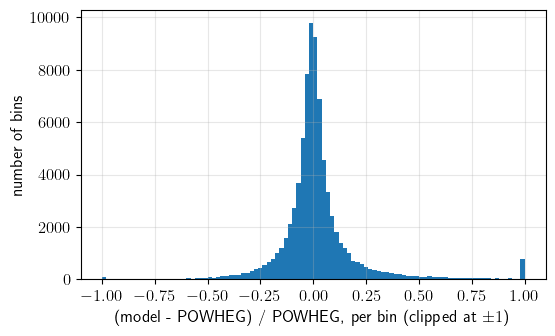

In [20]:
y_all = np.concatenate([y for total, x, y, f, *theta in data])
f_all = np.concatenate([f for total, x, y, f, *theta in data])
good  = f_all > 0
r = (y_all[good] - f_all[good]) / f_all[good]

negative = (y_all < 0).sum()
print(f'bins where the model predicts a negative cross section: {negative} of {len(y_all)}')
if negative:
    print(f'  most negative: {y_all.min():.2e} pb')
print()
print('relative difference (model - POWHEG) / POWHEG, over all bins of all holdout spectra')
for q in (0.5, 0.9, 0.99):
    print(f'  {int(q * 100):2d}% of bins within {np.quantile(np.abs(r), q):.3f}')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(np.clip(r, -1, 1), bins=100)
ax.set_xlabel('(model - POWHEG) / POWHEG, per bin (clipped at $\\pm1$)')
ax.set_ylabel('number of bins')
ax.grid(alpha=0.3)
plt.show()

## Summary

In [21]:
n_fail = sum(not passed for name, passed, detail in RESULTS)
for name, passed, detail in RESULTS:
    print(f"{'PASS' if passed else 'FAIL'}  {name}")
print(f'\n{len(RESULTS) - n_fail} passed, {n_fail} failed')

PASS  1a no duplicate parameter points (as stored)
PASS  1a no duplicate parameter points (float32)
PASS  1b no pair of points closer than 1e-06 (standardised units)
PASS  1c no two parameter points share an identical spectrum
PASS  2a holdout file has 1000 spectra
PASS  2a holdout IDs are distinct
PASS  2a training file has 3999 spectra
PASS  2a training rows = non-zero bins of the training spectra
PASS  2b no ID is in both the holdout and the training file
PASS  2b together they cover every POWHEG spectrum exactly once
PASS  2c no parameter point is in both files (float32 values)
PASS  2d holdout coefficients equal the POWHEG coefficients
PASS  2d holdout spectra equal the POWHEG spectra
PASS  2d training coefficients equal the POWHEG coefficients
PASS  2d every training mass is a bin centre in bins 17-96
PASS  2d training cross sections equal POWHEG row ID, bin k
PASS  2d each spectrum appears once per non-zero bin, no bin twice
PASS  2e heft_train.ipynb names only the training file